# Proyecto final – Analítica de datos con CRISP-DM
## Riesgo académico en Saber Pro (Datos Abiertos Colombia, ID `u37r-hjmu`)
**Curso:** Computación 3 – Introducción a la Analítica de Datos · Universidad de los Llanos  
**Autores:** Joshua Esteban Martínez Carvajal · Cristian Camilo Soto Robles

### Contenido
| Sección | Fase CRISP-DM |
|---|---|
| 0 | Configuración |
| 1 | Comprensión del negocio |
| 2 | Comprensión de los datos (población, muestra, calidad, representatividad) |
| 3 | Preparación de los datos (variables derivadas, partición, exploración) |
| 4 | Modelado |
| 5 | Evaluación (test, calibración, niveles de riesgo, importancias, equidad) |
| 6 | Despliegue (modelo, app Streamlit, entregables) |

## 0. Configuración

In [1]:
import requests, random, warnings, joblib, os, time, json, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
N_MUESTRA = 155_000
BLOQUE = 1_000
MIN_FILAS_PERIODO = 50_000
ARCHIVO_MUESTRA = "muestra_saberpro_150k.csv"
FORZAR_DESCARGA = False

for d in ("figs", "resultados"):
    os.makedirs(d, exist_ok=True)

BASE = "https://www.datos.gov.co/resource/u37r-hjmu.json"
def soda(**p):
    """Consulta a la API de datos.gov.co con 3 reintentos."""
    for intento in range(3):
        try:
            r = requests.get(BASE, params=p, timeout=120)
            r.raise_for_status()
            return r.json()
        except requests.RequestException:
            if intento == 2:
                raise
            time.sleep(2 * (intento + 1))

SCORES = ["mod_razona_cuantitat_punt", "mod_lectura_critica_punt",
          "mod_ingles_punt", "mod_competen_ciudada_punt"]          # solo para construir el objetivo (NO son predictores)
CAT = ["estu_genero", "estu_depto_reside", "fami_estratovivienda", "fami_educacionpadre",
       "fami_educacionmadre", "fami_tieneinternet", "fami_tienecomputador", "fami_tieneautomovil",
       "fami_tienelavadora", "estu_horassemanatrabaja", "estu_valormatriculauniversidad",
       "estu_metodo_prgm", "inst_caracter_academico", "inst_origen", "estu_nucleo_pregrado"]
NUM = ["edad"]
COLS = ["periodo", "estu_fechanacimiento"] + CAT + SCORES

## 1. Comprensión del negocio (CRISP-DM, fase 1)

**Problema.** El examen Saber Pro mide competencias genéricas de quienes terminan un pregrado. Las instituciones necesitan identificar a tiempo qué perfiles tienen mayor probabilidad de bajo desempeño para focalizar acompañamiento académico.

**Objetivo 1 (predictivo, se despliega en la app).** Estimar la probabilidad de que un estudiante quede en el 25 % inferior del puntaje compuesto, usando solo variables socioeconómicas, institucionales y del programa.

**Objetivo 2 (explicativo).** Identificar qué factores pesan más en ese riesgo y si el modelo rinde de forma pareja entre subgrupos (género, origen de la institución, estrato).

**Definiciones.**
- *Puntaje compuesto*: promedio simple de razonamiento cuantitativo, lectura crítica, inglés y competencias ciudadanas. Es un proxy propio, no el puntaje global oficial del ICFES.
- *Riesgo*: puntaje compuesto ≤ percentil 25 de la muestra de entrenamiento.

**Criterios de éxito.** ROC-AUC claramente superior al baseline (0,50); probabilidades calibradas (la probabilidad estimada se parece al riesgo observado); desempeño similar entre subgrupos; app funcional.

**Consideraciones éticas.** La herramienta es de apoyo y no debe usarse para excluir estudiantes. Las asociaciones encontradas no son relaciones causales.

## 2. Comprensión de los datos (CRISP-DM, fase 2)
### 2.1 Población completa por periodo (consulta agregada en el servidor)

In [2]:
pob = pd.DataFrame(soda(**{"$select": "periodo, count(*) as n", "$group": "periodo", "$order": "periodo"}))
pob["n"] = pob["n"].astype(int)
pob.to_csv("resultados/poblacion_por_periodo.csv", index=False)
print(f"Registros en la población: {pob['n'].sum():,}")
pob

Registros en la población: 1,217,482


,periodo,n
0,20183,235224
1,20184,373
2,20194,2076
3,20195,258452
4,20196,228
5,20202,680
6,20203,245775
7,20212,247099
8,20213,1670
9,20222,97889


### 2.2 Muestra estratificada por periodo (asignación proporcional)
Se usan los periodos con más de 50.000 registros. Cada periodo aporta a la muestra en proporción a su tamaño real, y dentro de cada periodo se descargan bloques de filas elegidos al azar. Así la muestra reproduce la composición de la población sin necesidad de ponderar.

In [3]:
PERIODOS = pob.loc[pob["n"] > MIN_FILAS_PERIODO, "periodo"].tolist()
N_POR_PERIODO = pob.set_index("periodo").loc[PERIODOS, "n"]
print("Periodos usados:", PERIODOS, "| registros en esos periodos:", f"{N_POR_PERIODO.sum():,}")

def filtro_periodo(p):
    for w in (f"periodo={p}", f"periodo='{p}'"):
        try:
            soda(**{"$select": "count(*)", "$where": w})
            return w
        except requests.RequestException:
            continue
    raise ValueError(f"No pude filtrar el periodo {p}")

def muestra_periodo(p, n_filas, seed=SEED):
    w = filtro_periodo(p)
    N = int(N_POR_PERIODO[p])
    posibles = list(range(0, max(N - BLOQUE, 1), BLOQUE))
    n_bloques = min(max(1, round(n_filas / BLOQUE)), len(posibles))
    offs = random.Random(seed).sample(posibles, n_bloques)
    partes = []
    for i, o in enumerate(offs, 1):
        partes += soda(**{"$select": ",".join(COLS), "$where": w, "$order": ":id",
                          "$limit": BLOQUE, "$offset": o})
        if i % 10 == 0:
            print(f"   periodo {p}: {i}/{n_bloques} bloques")
    return pd.DataFrame(partes)

if os.path.exists(ARCHIVO_MUESTRA) and not FORZAR_DESCARGA:
    df = pd.read_csv(ARCHIVO_MUESTRA, dtype=str)
    print("Muestra cargada desde archivo guardado.")
else:
    t0 = time.time()
    partes = []
    for p in PERIODOS:
        n_p = N_MUESTRA * N_POR_PERIODO[p] / N_POR_PERIODO.sum()
        print(f"Descargando periodo {p} (~{n_p:,.0f} filas)...")
        partes.append(muestra_periodo(p, n_p))
    df = pd.concat(partes, ignore_index=True)
    df.to_csv(ARCHIVO_MUESTRA, index=False)
    print(f"Descarga terminada en {(time.time() - t0) / 60:.1f} min")

print("Tamaño de la muestra:", df.shape)
df["periodo"].value_counts().sort_index()

Periodos usados: ['20183', '20195', '20203', '20212', '20222', '20225'] | registros en esos periodos: 1,210,721
Descargando periodo 20183 (~30,114 filas)...
   periodo 20183: 10/30 bloques
   periodo 20183: 20/30 bloques
   periodo 20183: 30/30 bloques
Descargando periodo 20195 (~33,088 filas)...
   periodo 20195: 10/33 bloques
   periodo 20195: 20/33 bloques
   periodo 20195: 30/33 bloques
Descargando periodo 20203 (~31,465 filas)...
   periodo 20203: 10/31 bloques
   periodo 20203: 20/31 bloques
   periodo 20203: 30/31 bloques
Descargando periodo 20212 (~31,634 filas)...
   periodo 20212: 10/32 bloques
   periodo 20212: 20/32 bloques
   periodo 20212: 30/32 bloques
Descargando periodo 20222 (~12,532 filas)...
   periodo 20222: 10/13 bloques
Descargando periodo 20225 (~16,167 filas)...
   periodo 20225: 10/16 bloques
Descarga terminada en 9.1 min
Tamaño de la muestra: (155000, 21)


,count
periodo,
20183,30000
20195,33000
20203,31000
20212,32000
20222,13000
20225,16000


### 2.3 Calidad de los datos: nulos por variable y periodo

In [4]:
nulos_pct = (df[CAT + SCORES].isna().groupby(df["periodo"]).mean() * 100).round(1).T
nulos_pct.to_csv("resultados/nulos_por_periodo.csv")
print("Nulos (%) por variable y periodo:")
nulos_pct

Nulos (%) por variable y periodo:


periodo,20183,20195,20203,20212,20222,20225
estu_genero,0.0,0.0,0.0,0.0,0.0,0.0
estu_depto_reside,0.3,0.8,0.0,0.0,0.0,0.0
fami_estratovivienda,7.0,6.0,1.9,3.3,3.1,4.0
fami_educacionpadre,5.3,4.1,1.5,2.2,2.7,3.5
fami_educacionmadre,5.3,4.2,1.6,2.4,2.7,3.6
fami_tieneinternet,5.5,4.3,2.0,3.4,3.2,4.1
fami_tienecomputador,5.8,4.6,3.0,8.5,3.6,4.5
fami_tieneautomovil,5.9,4.7,4.4,10.3,5.8,5.3
fami_tienelavadora,5.9,4.6,3.1,9.4,3.7,4.7
estu_horassemanatrabaja,6.1,4.8,2.8,4.1,3.9,5.1


### 2.4 Representatividad: muestra frente a población (porcentajes por categoría)

In [5]:
def where_periodos(ps):
    quoted = "'" in filtro_periodo(ps[0])
    lista = ",".join(f"'{p}'" if quoted else str(p) for p in ps)
    return f"periodo in({lista})"

comparacion = []
try:
    wp = where_periodos(PERIODOS)
    for var in ["estu_genero", "inst_origen", "inst_caracter_academico", "estu_metodo_prgm"]:
        poblac = pd.DataFrame(soda(**{"$select": f"{var}, count(*) as n", "$where": wp, "$group": var}))
        poblac["n"] = poblac["n"].astype(int)
        poblac = (poblac.set_index(var)["n"] / poblac["n"].sum() * 100).rename("Población %")
        muest = (df[var].value_counts(normalize=True) * 100).rename("Muestra %")
        t = pd.concat([poblac, muest], axis=1).fillna(0).round(2)
        t["Diferencia (pp)"] = (t["Muestra %"] - t["Población %"]).round(2)
        t.insert(0, "Variable", var)
        comparacion.append(t.reset_index().rename(columns={"index": "Categoría", var: "Categoría"}))
    comparacion = pd.concat(comparacion, ignore_index=True)
    comparacion.to_csv("resultados/representatividad_muestra_vs_poblacion.csv", index=False)
    print("Diferencia absoluta máxima (puntos porcentuales):", comparacion["Diferencia (pp)"].abs().max())
except Exception as e:
    print("No se pudo calcular la comparación con la población:", e)
comparacion

Diferencia absoluta máxima (puntos porcentuales): 0.15


,Categoría,Variable,Población %,Muestra %,Diferencia (pp)
0,F,estu_genero,59.03,59.08,0.05
1,M,estu_genero,40.96,40.92,-0.04
2,NaN,estu_genero,0.01,0.00,-0.01
3,NO OFICIAL - CORPORACIÓN,inst_origen,35.22,35.23,0.01
4,NO OFICIAL - FUNDACIÓN,inst_origen,31.32,31.24,-0.08
5,OFICIAL DEPARTAMENTAL,inst_origen,15.35,15.26,-0.09
6,OFICIAL MUNICIPAL,inst_origen,2.17,2.17,0.00
7,OFICIAL NACIONAL,inst_origen,15.88,16.03,0.15
8,REGIMEN ESPECIAL,inst_origen,0.07,0.06,-0.01
9,INSTITUCIÓN TECNOLÓGICA,inst_caracter_academico,1.75,1.74,-0.01


## 3. Preparación de los datos (CRISP-DM, fase 3)
### 3.1 Variables derivadas, objetivo y partición train/test

In [6]:
from sklearn.model_selection import train_test_split

# Tipos numéricos y filas completas en los puntajes
for c in SCORES:
    df[c] = pd.to_numeric(df[c], errors="coerce")
n_antes = len(df)
df = df.dropna(subset=SCORES).copy()
print(f"Filas eliminadas por puntajes nulos: {n_antes - len(df)}")

# Edad al presentar el examen
s = df["estu_fechanacimiento"].astype(str)
nac = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
nac = nac.fillna(pd.to_datetime(s, errors="coerce"))
anio = df["periodo"].astype(str).str[:4].astype(int)
df["edad"] = (anio - nac.dt.year).where(lambda x: x.between(16, 70))

# Puntaje compuesto propio (promedio simple de 4 módulos; NO es el puntaje global oficial del ICFES)
df["puntaje_compuesto"] = df[SCORES].mean(axis=1)

# Partición estratificada por periodo. El umbral del cuartil se calcula SOLO con train.
tr, te = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["periodo"])
UMBRAL_Q1 = tr["puntaje_compuesto"].quantile(0.25)
y_tr = (tr["puntaje_compuesto"] <= UMBRAL_Q1).astype(int)
y_te = (te["puntaje_compuesto"] <= UMBRAL_Q1).astype(int)
X_tr, X_te = tr[CAT + NUM], te[CAT + NUM]
BASE_RIESGO = float(y_tr.mean())

print(f"Train = {len(tr):,} | Test = {len(te):,} | umbral del cuartil inferior = {UMBRAL_Q1:.1f} | % riesgo en train = {BASE_RIESGO:.1%}")
print("\nNulos por predictor en train (%):")
print((X_tr.isna().mean() * 100).round(1).sort_values(ascending=False).head(8))

Filas eliminadas por puntajes nulos: 16
Train = 123,987 | Test = 30,997 | umbral del cuartil inferior = 129.2 | % riesgo en train = 25.1%

Nulos por predictor en train (%):
fami_tieneautomovil        6.2
fami_tienelavadora         5.5
fami_tienecomputador       5.2
estu_horassemanatrabaja    4.5
fami_estratovivienda       4.4
fami_tieneinternet         3.8
fami_educacionmadre        3.3
fami_educacionpadre        3.2
dtype: float64


### 3.2 Diccionario de las variables usadas

In [7]:
roles = {**{c: "Predictor categórico" for c in CAT}, "edad": "Predictor numérico (derivado de la fecha de nacimiento)",
         **{c: "Insumo del puntaje compuesto (no es predictor)" for c in SCORES},
         "puntaje_compuesto": "Derivada: promedio de los 4 módulos", "periodo": "Estratificación y partición"}
dic = pd.DataFrame({"Variable": list(roles), "Rol": list(roles.values())})
dic["Tipo"] = dic["Variable"].map(lambda c: "numérico" if c in SCORES + NUM + ["puntaje_compuesto"] else "categórico")
dic["Nulos (%)"] = dic["Variable"].map(lambda c: round(df[c].isna().mean() * 100, 1))
dic["Categorías distintas"] = dic["Variable"].map(lambda c: df[c].nunique() if c in CAT + ["periodo"] else np.nan)
dic.to_csv("resultados/diccionario_variables.csv", index=False)
dic

,Variable,Rol,Tipo,Nulos (%),Categorías distintas
0,estu_genero,Predictor categórico,categórico,0.0,2.0
1,estu_depto_reside,Predictor categórico,categórico,0.2,34.0
2,fami_estratovivienda,Predictor categórico,categórico,4.4,7.0
3,fami_educacionpadre,Predictor categórico,categórico,3.2,12.0
4,fami_educacionmadre,Predictor categórico,categórico,3.3,12.0
5,fami_tieneinternet,Predictor categórico,categórico,3.8,2.0
6,fami_tienecomputador,Predictor categórico,categórico,5.2,2.0
7,fami_tieneautomovil,Predictor categórico,categórico,6.2,2.0
8,fami_tienelavadora,Predictor categórico,categórico,5.5,2.0
9,estu_horassemanatrabaja,Predictor categórico,categórico,4.5,5.0


### 3.3 Exploración del puntaje y del objetivo

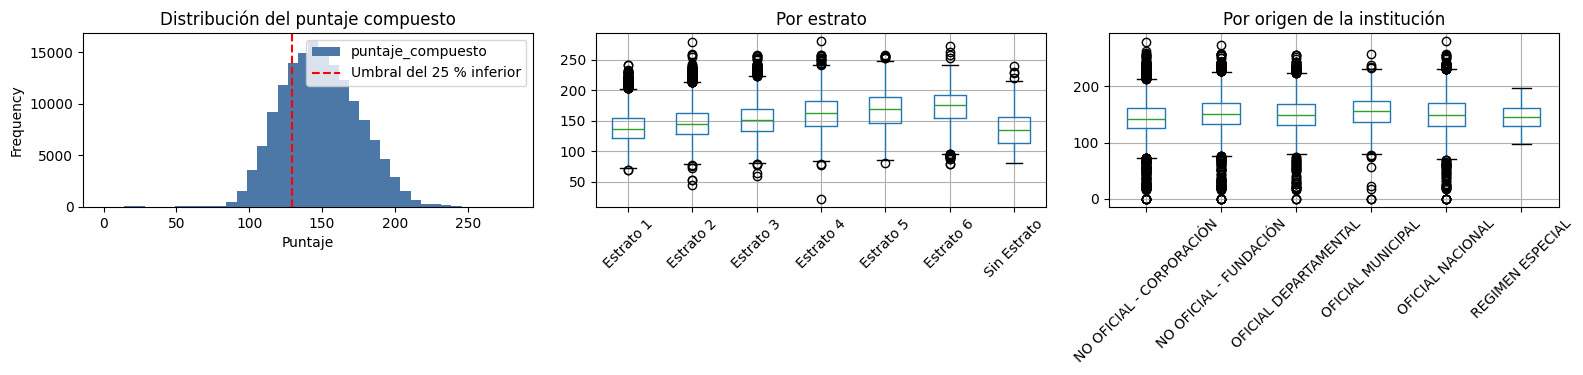

,categoria,variable,n,tasa_riesgo
0,Estrato 1,fami_estratovivienda,26669,0.381
1,Estrato 2,fami_estratovivienda,52346,0.267
2,Estrato 3,fami_estratovivienda,46451,0.199
3,Estrato 4,fami_estratovivienda,14243,0.137
4,Estrato 5,fami_estratovivienda,5002,0.112
5,Estrato 6,fami_estratovivienda,2750,0.098
6,Sin Estrato,fami_estratovivienda,705,0.441
7,NO OFICIAL - CORPORACIÓN,inst_origen,54601,0.299
8,NO OFICIAL - FUNDACIÓN,inst_origen,48420,0.214
9,OFICIAL DEPARTAMENTAL,inst_origen,23653,0.231


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["puntaje_compuesto"].plot.hist(bins=40, ax=ax[0], color="#4C78A8")
ax[0].axvline(UMBRAL_Q1, color="red", ls="--", label="Umbral del 25 % inferior"); ax[0].legend()
ax[0].set_title("Distribución del puntaje compuesto"); ax[0].set_xlabel("Puntaje")
df.boxplot("puntaje_compuesto", by="fami_estratovivienda", ax=ax[1], rot=45); ax[1].set_title("Por estrato"); ax[1].set_xlabel("")
df.boxplot("puntaje_compuesto", by="inst_origen", ax=ax[2], rot=45); ax[2].set_title("Por origen de la institución"); ax[2].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.savefig("figs/eda_puntaje.png", dpi=200); plt.show()

# Tasa de riesgo observada por variable clave (insumo para la Discusión)
tasas = []
for v in ["fami_estratovivienda", "inst_origen", "estu_metodo_prgm", "fami_tieneinternet", "estu_horassemanatrabaja"]:
    t = df.assign(riesgo=(df["puntaje_compuesto"] <= UMBRAL_Q1)).groupby(v)["riesgo"].agg(["size", "mean"]).round(3)
    t.columns = ["n", "tasa_riesgo"]; t.insert(0, "variable", v); tasas.append(t.reset_index().rename(columns={v: "categoria"}))
tasas = pd.concat(tasas, ignore_index=True)
tasas.to_csv("resultados/tasa_riesgo_por_categoria.csv", index=False)
tasas

## 4. Modelado (CRISP-DM, fase 4)
Todo el preprocesamiento va dentro de un `Pipeline`, de modo que en la validación cruzada se ajusta solo con los datos de entrenamiento de cada partición (sin fuga de información). Se compara contra un baseline y se evalúa con validación cruzada estratificada de 5 particiones. No se usan pesos de clase: así las probabilidades quedan calibradas y el desbalance (25 % / 75 %) se maneja con el umbral de decisión.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

def preproc():
    return ColumnTransformer([
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Sin dato")),
                          ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False))]), CAT),
        ("num", SimpleImputer(strategy="median"), NUM)])

modelos = {
    "Baseline (clase mayoritaria)": DummyClassifier(strategy="prior"),
    "Regresión logística": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    "Gradient Boosting (Hist)": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

filas = []
for nombre, m in modelos.items():
    t0 = time.time()
    r = cross_validate(Pipeline([("pre", preproc()), ("m", m)]), X_tr, y_tr, cv=cv,
                       scoring=["roc_auc", "average_precision"], n_jobs=1)
    filas.append({"Modelo": nombre,
                  "ROC-AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
                  "PR-AUC": f"{r['test_average_precision'].mean():.3f} ± {r['test_average_precision'].std():.3f}",
                  "Tiempo (s)": round(time.time() - t0), "_auc": r["test_roc_auc"].mean()})
    print(f"{nombre}: listo ({filas[-1]['Tiempo (s)']} s)")

tabla_cv = pd.DataFrame(filas).sort_values("_auc", ascending=False)
mejor = tabla_cv.iloc[0]["Modelo"]
tabla_cv.drop(columns="_auc").to_csv("resultados/comparacion_modelos_cv.csv", index=False)
print("\nMejor modelo en validación cruzada:", mejor)
tabla_cv.drop(columns="_auc")

Baseline (clase mayoritaria): listo (24 s)
Regresión logística: listo (185 s)
Random Forest: listo (96 s)
Gradient Boosting (Hist): listo (205 s)

Mejor modelo en validación cruzada: Gradient Boosting (Hist)


,Modelo,ROC-AUC,PR-AUC,Tiempo (s)
3,Gradient Boosting (Hist),0.780 ± 0.002,0.542 ± 0.005,205
2,Random Forest,0.768 ± 0.002,0.520 ± 0.006,96
1,Regresión logística,0.766 ± 0.002,0.519 ± 0.005,185
0,Baseline (clase mayoritaria),0.500 ± 0.000,0.251 ± 0.000,24


## 5. Evaluación (CRISP-DM, fase 5)
### 5.1 Ajuste final y resultados en test

TEST -> ROC-AUC = 0.777 | PR-AUC = 0.528 | umbral de clasificación = 0.26
              precision    recall  f1-score   support

   No riesgo       0.88      0.69      0.77     23286
      Riesgo       0.43      0.71      0.54      7711

    accuracy                           0.70     30997
   macro avg       0.66      0.70      0.66     30997
weighted avg       0.77      0.70      0.72     30997



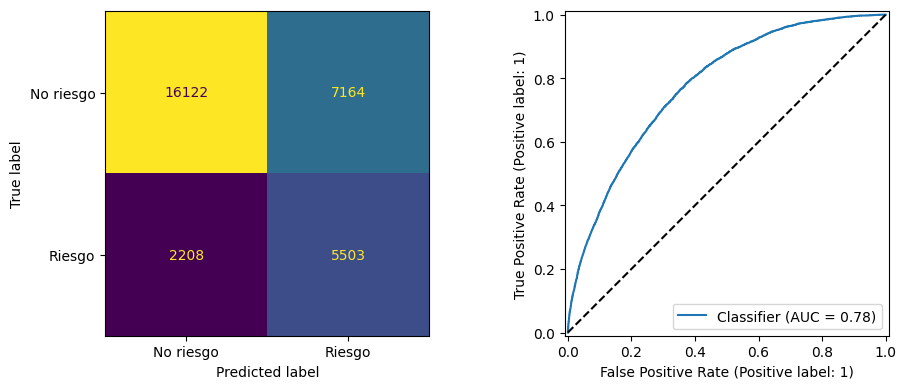

In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve)

pipe = Pipeline([("pre", preproc()), ("m", modelos[mejor])])

# Predicciones fuera de muestra sobre TRAIN: sirven para elegir umbrales sin tocar el test
oof = cross_val_predict(pipe, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
p_, r_, t_ = precision_recall_curve(y_tr, oof)
f1 = 2 * p_[:-1] * r_[:-1] / (p_[:-1] + r_[:-1] + 1e-9)
UMBRAL_PROB = float(t_[f1.argmax()])          # umbral de clasificación (maximiza F1)

pipe.fit(X_tr, y_tr)
proba = pipe.predict_proba(X_te)[:, 1]
pred = (proba >= UMBRAL_PROB).astype(int)
AUC = roc_auc_score(y_te, proba); PRAUC = average_precision_score(y_te, proba)
print(f"TEST -> ROC-AUC = {AUC:.3f} | PR-AUC = {PRAUC:.3f} | umbral de clasificación = {UMBRAL_PROB:.2f}")
print(classification_report(y_te, pred, target_names=["No riesgo", "Riesgo"]))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["No riesgo", "Riesgo"], ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_te, proba, ax=ax[1]); ax[1].plot([0, 1], [0, 1], "k--")
plt.tight_layout(); plt.savefig("figs/evaluacion.png", dpi=200); plt.show()

tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
metricas = {"modelo": mejor, "n_muestra": int(len(df)), "n_train": int(len(tr)), "n_test": int(len(te)),
            "umbral_q1_puntaje": float(UMBRAL_Q1), "riesgo_base_train": BASE_RIESGO,
            "roc_auc_test": float(AUC), "pr_auc_test": float(PRAUC), "umbral_clasificacion": UMBRAL_PROB,
            "precision_riesgo": float(tp / (tp + fp)), "recall_riesgo": float(tp / (tp + fn)),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

### 5.2 Calibración y niveles de riesgo para la app
Se comprueba si la probabilidad estimada coincide con el riesgo observado. Los cortes de los niveles **Bajo / Medio / Alto** se definen con las predicciones fuera de muestra del *train*:
- **Bajo:** hasta donde el riesgo observado sea la mitad del promedio o menos.
- **Alto:** desde donde el riesgo observado sea el doble del promedio o más.

Cortes -> Bajo: p < 0.13 | Alto: p >= 0.50
Cortes elegidos -> Bajo: p <= 0.13 | Alto: p >= 0.50

Calibración en test (probabilidad media vs. riesgo real):
                  n  prob_media  riesgo_real
tramo                                       
(-0.001, 0.1]  8019       0.055        0.043
(0.1, 0.15]    3440       0.124        0.126
(0.15, 0.2]    3109       0.175        0.168
(0.2, 0.25]    2938       0.225        0.237
(0.25, 0.3]    2741       0.274        0.285
(0.3, 0.4]     4266       0.347        0.347
(0.4, 0.5]     2890       0.447        0.440
(0.5, 0.6]     1850       0.546        0.537
(0.6, 1.0]     1744       0.693        0.683

Niveles de riesgo en test:
           n  riesgo_real  veces_riesgo_promedio
nivel                                           
Bajo   10166        0.060                   0.24
Medio  17237        0.285                   1.15
Alto    3594        0.608                   2.44


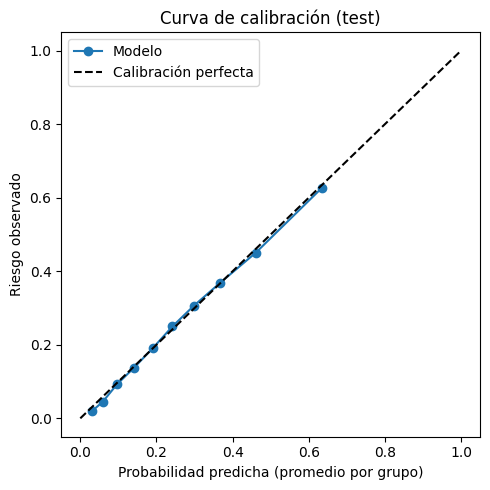

,n,riesgo_real,veces_riesgo_promedio
nivel,,,
Bajo,10166,0.060,0.24
Medio,17237,0.285,1.15
Alto,3594,0.608,2.44


In [19]:
from sklearn.calibration import calibration_curve

# Cortes de los niveles (con OOF de train)
def tasa(mask):
    return y_tr.values[mask].mean() if mask.sum() >= 200 else np.nan
grid = np.round(np.arange(0.05, 0.81, 0.01), 2)
bajos = [c for c in grid if tasa(oof <= c) <= 0.5 * BASE_RIESGO]
altos = [c for c in grid if tasa(oof >= c) >= 2.0 * BASE_RIESGO]
CORTE_BAJO = round(0.5 * BASE_RIESGO, 2)
CORTE_ALTO = round(2.0 * BASE_RIESGO, 2)
print(f"Cortes -> Bajo: p < {CORTE_BAJO:.2f} | Alto: p >= {CORTE_ALTO:.2f}")
print(f"Cortes elegidos -> Bajo: p <= {CORTE_BAJO:.2f} | Alto: p >= {CORTE_ALTO:.2f}")

# Verificación en test
tab = pd.DataFrame({"p": proba, "y": y_te.values})
tab["tramo"] = pd.cut(tab["p"], [0, .10, .15, .20, .25, .30, .40, .50, .60, 1], include_lowest=True)
calib = tab.groupby("tramo", observed=True).agg(n=("y", "size"), prob_media=("p", "mean"), riesgo_real=("y", "mean")).round(3)
calib.to_csv("resultados/calibracion_por_tramos.csv")
print("\nCalibración en test (probabilidad media vs. riesgo real):"); print(calib)

tab["nivel"] = pd.cut(tab["p"], [0, CORTE_BAJO, CORTE_ALTO, 1.0001], labels=["Bajo", "Medio", "Alto"], include_lowest=True, right=False)
niveles = tab.groupby("nivel", observed=True).agg(n=("y", "size"), riesgo_real=("y", "mean")).round(3)
niveles["veces_riesgo_promedio"] = (niveles["riesgo_real"] / y_te.mean()).round(2)
niveles.to_csv("resultados/niveles_de_riesgo_test.csv")
print("\nNiveles de riesgo en test:"); print(niveles)

fr, mp = calibration_curve(tab["y"], tab["p"], n_bins=10, strategy="quantile")
plt.figure(figsize=(5, 5)); plt.plot(mp, fr, "o-", label="Modelo"); plt.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")
plt.xlabel("Probabilidad predicha (promedio por grupo)"); plt.ylabel("Riesgo observado"); plt.legend(); plt.title("Curva de calibración (test)")
plt.tight_layout(); plt.savefig("figs/calibracion.png", dpi=200); plt.show()
metricas.update({"corte_bajo": CORTE_BAJO, "corte_alto": CORTE_ALTO})
niveles

### 5.3 Importancia de las variables (Objetivo 2)
Importancia por permutación sobre las variables originales. Con variables correlacionadas (estrato, educación de los padres) tiende a subestimar a cada una por separado; son asociaciones, no causas.

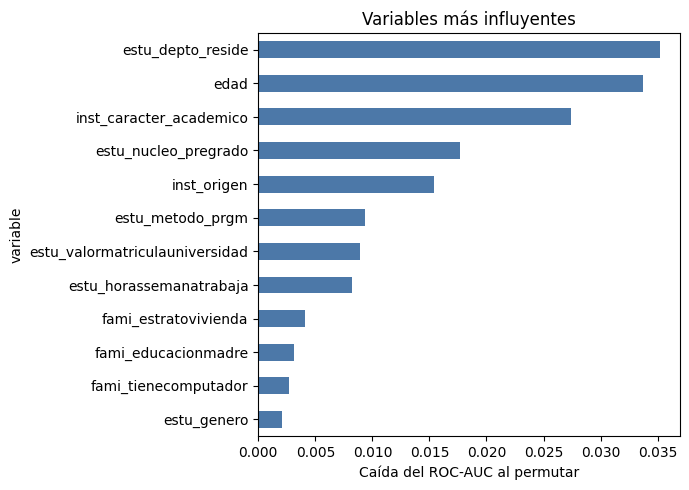

,variable,caida_auc,desv
1,estu_depto_reside,0.0352,0.0016
15,edad,0.0338,0.0015
12,inst_caracter_academico,0.0274,0.0018
14,estu_nucleo_pregrado,0.0176,0.0023
13,inst_origen,0.0154,0.0009
11,estu_metodo_prgm,0.0093,0.0014
10,estu_valormatriculauniversidad,0.0089,0.0014
9,estu_horassemanatrabaja,0.0082,0.0001
2,fami_estratovivienda,0.0041,0.0009
4,fami_educacionmadre,0.0031,0.0012


In [12]:
from sklearn.inspection import permutation_importance

sub = X_te.sample(min(10_000, len(X_te)), random_state=SEED)
pi = permutation_importance(pipe, sub, y_te.loc[sub.index], scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=-1)
imp_all = pd.DataFrame({"variable": X_te.columns, "caida_auc": pi.importances_mean, "desv": pi.importances_std}).sort_values("caida_auc", ascending=False)
imp_all.round(4).to_csv("resultados/importancia_variables.csv", index=False)

imp = imp_all.set_index("variable")["caida_auc"].sort_values().tail(12)
imp.plot.barh(figsize=(7, 5), color="#4C78A8"); plt.xlabel("Caída del ROC-AUC al permutar"); plt.title("Variables más influyentes")
plt.tight_layout(); plt.savefig("figs/importancias.png", dpi=200); plt.show()
imp_all.round(4).head(12)

### 5.4 Equidad: desempeño por subgrupo

In [20]:
res = te.assign(y=y_te, proba=proba)
filas = []
for g in ["estu_genero", "inst_origen", "fami_estratovivienda"]:
    for k, d in res.groupby(g):
        if len(d) >= 100 and d["y"].nunique() == 2:
            filas.append({"variable": g, "grupo": k, "n": len(d), "AUC": round(roc_auc_score(d["y"], d["proba"]), 3),
                          "riesgo_real": round(d["y"].mean(), 3), "prob_media": round(d["proba"].mean(), 3)})
subgrupos = pd.DataFrame(filas)
subgrupos.to_csv("resultados/desempeno_por_subgrupo.csv", index=False)
json.dump(metricas, open("resultados/metricas_finales.json", "w"), indent=2, ensure_ascii=False)
subgrupos

,variable,grupo,n,AUC,riesgo_real,prob_media
0,estu_genero,F,18422,0.776,0.274,0.280
1,estu_genero,M,12571,0.772,0.212,0.211
2,inst_origen,NO OFICIAL - CORPORACIÓN,11060,0.751,0.294,0.296
3,inst_origen,NO OFICIAL - FUNDACIÓN,9772,0.766,0.211,0.218
4,inst_origen,OFICIAL DEPARTAMENTAL,4645,0.803,0.237,0.233
5,inst_origen,OFICIAL MUNICIPAL,664,0.817,0.179,0.196
6,inst_origen,OFICIAL NACIONAL,4840,0.807,0.244,0.247
7,fami_estratovivienda,Estrato 1,5387,0.751,0.366,0.381
8,fami_estratovivienda,Estrato 2,10410,0.752,0.270,0.268
9,fami_estratovivienda,Estrato 3,9358,0.753,0.197,0.202


## 6. Despliegue (CRISP-DM, fase 6)
### 6.1 Guardar el modelo

In [21]:
opciones = {c: sorted(df[c].dropna().astype(str).unique().tolist()) for c in CAT}
joblib.dump({"modelo": pipe, "umbral": UMBRAL_PROB, "opciones": opciones, "cat": CAT, "num": NUM,
             "auc_test": float(AUC), "modelo_nombre": mejor,
             "cortes": (CORTE_BAJO, CORTE_ALTO), "base": BASE_RIESGO}, "modelo_riesgo.joblib", compress=3)
print("Guardado: modelo_riesgo.joblib (%.1f MB)" % (os.path.getsize("modelo_riesgo.joblib") / 1e6))

Guardado: modelo_riesgo.joblib (0.3 MB)


### 6.2 Aplicación Streamlit (`app.py`)

In [15]:
%%writefile app.py
import streamlit as st, joblib, pandas as pd

st.set_page_config(page_title="Riesgo académico – Saber Pro", page_icon="🎓")
art = joblib.load("modelo_riesgo.joblib")

ETIQ = {"estu_genero": "Género", "estu_depto_reside": "Departamento de residencia",
        "fami_estratovivienda": "Estrato de la vivienda", "fami_educacionpadre": "Educación del padre",
        "fami_educacionmadre": "Educación de la madre", "fami_tieneinternet": "¿Tiene internet?",
        "fami_tienecomputador": "¿Tiene computador?", "fami_tieneautomovil": "¿Tiene automóvil?",
        "fami_tienelavadora": "¿Tiene lavadora?", "estu_horassemanatrabaja": "Horas semanales de trabajo",
        "estu_valormatriculauniversidad": "Valor de la matrícula", "estu_metodo_prgm": "Modalidad del programa",
        "inst_caracter_academico": "Carácter académico de la institución", "inst_origen": "Origen de la institución",
        "estu_nucleo_pregrado": "Núcleo del pregrado"}

st.title("🎓 Estimador de riesgo académico – Saber Pro")
st.caption("Estima la probabilidad de quedar en el 25 % inferior del puntaje compuesto a partir del contexto "
           "socioeconómico, institucional y del programa. Es una herramienta de apoyo, no un diagnóstico individual.")

with st.form("formulario"):
    c1, c2 = st.columns(2)
    datos = {}
    for i, c in enumerate(art["cat"]):
        datos[c] = (c1 if i % 2 == 0 else c2).selectbox(ETIQ.get(c, c), art["opciones"][c])
    datos["edad"] = c1.number_input("Edad", min_value=16, max_value=70, value=24)
    enviado = st.form_submit_button("Calcular riesgo")

if enviado:
    p = float(art["modelo"].predict_proba(pd.DataFrame([datos]))[:, 1][0])
    bajo, alto = art["cortes"]
    st.metric("Probabilidad estimada de riesgo", f"{p:.1%}",
              delta=f"{p / art['base']:.1f}× el riesgo promedio ({art['base']:.0%})", delta_color="off")
    st.progress(min(p, 1.0))
    if p >= alto:
        st.error("Riesgo ALTO: se recomienda priorizar acompañamiento académico (tutorías, nivelación, bienestar).")
    elif p >= bajo:
        st.warning("Riesgo MEDIO: conviene hacer seguimiento.")
    else:
        st.success("Riesgo BAJO.")
    st.caption(f"Modelo: {art['modelo_nombre']} · ROC-AUC en prueba: {art['auc_test']:.3f}. "
               "'Riesgo' = quedar en el 25 % inferior del puntaje compuesto de la muestra.")

Writing app.py


### 6.3 `requirements.txt` con las versiones exactas con las que se entrenó el modelo

In [16]:
import sklearn
with open("requirements.txt", "w") as f:
    f.write(f"streamlit\nscikit-learn=={sklearn.__version__}\npandas\nnumpy\njoblib\n")
print(open("requirements.txt").read())

streamlit
scikit-learn==1.6.1
pandas
numpy
joblib



### 6.4 Probar la app dentro de Colab (opcional)


In [17]:
!pip -q install streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!pkill -f streamlit
!streamlit run app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false &>/content/logs.txt &
!./cloudflared tunnel --url http://localhost:8501 --no-autoupdate

2026-11-13T20:01:01Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-13T20:01:01Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-13T20:01:05Z INF +--------------------------------------------------------------------------------------------+
2026-11-13T20:01:05Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-13T20:01:05Z INF |  https://bathrooms-unexpected-citizenship-wto.trycloud

### 6.5 Empaquetar los entregables

In [22]:
os.makedirs("entregables", exist_ok=True)
for f in ["app.py", "requirements.txt", "modelo_riesgo.joblib"]:
    shutil.copy(f, "entregables/")
for d in ["figs", "resultados"]:
    shutil.copytree(d, f"entregables/{d}", dirs_exist_ok=True)
shutil.make_archive("entregables_saberpro", "zip", "entregables")
print("Listo: entregables_saberpro.zip")
try:
    from google.colab import files
    files.download("entregables_saberpro.zip")
except ImportError:
    pass

Listo: entregables_saberpro.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>